# Neuro-Damköhler & Trans-Compartmental Permselectivity Framework in Alzheimer's Disease (ADNI)

**Complete Restart & Verification Pipeline**
This notebook restarts the entire ADNI multi-compartmental fluidic analysis from scratch using the local workspace dataset (`data-20261119T152706Z-1-001/data/`).

### Key Methodological Upgrades Addressing All Previous Reviewer Critiques:
1. **Fixes the Sign Convention:** Explicitly defines the **Neuro-Damköhler Index** ($Da_{\text{Tau}} = \ln[\text{Plasma p-tau217} / \text{CSF p-tau181}]$) and the **Control-Anchored Kinetic Divergence** ($\Delta Z_{\text{CN}} = Z_{\text{CN}}(\ln \text{Plasma p-tau217}) - Z_{\text{CN}}(\ln \text{CSF p-tau181})$), where **higher values = greater trans-compartmental kinetic runaway / impaired central containment**.
2. **Proves Identical-Analyte Physical Convergence (Critique #1 & #2):** Validates $Da_{\text{Tau}}$ and $\Delta Z_{\text{CN}}$ directly against **identical-analyte** trans-compartmental partition ratios ($\kappa_{A\beta40} = \ln[\text{Plasma } A\beta_{40} / \text{CSF } A\beta_{40}]$ and $\kappa_{A\beta42} = \ln[\text{Plasma } A\beta_{42} / \text{CSF } A\beta_{42}]$), demonstrating massive cross-molecule physical convergence ($\rho = 0.680, p = 5.26 \times 10^{-41}$).
3. **External Tri-Modal Structural, Glial, DTI, & Renal Anchoring (Critique #1):** Anchors the biofluid partition ratios against:
   - **Macro-CSF Capacitance (Structural MRI):** Ventricular Volume / ICV% ($N=379$) — showing significance **even in healthy amyloid-negative aging controls (`CN Aβ-`)** where standalone plasma p-tau217 completely fails!
   - **Microglial Containment:** CSF `sTREM2` ($N=101$)
   - **Astrocytic Perivascular Gliosis & Axonal Injury:** Plasma `GFAP` and `NfL` ($N=406$, Quanterix Simoa)
   - **White-Matter Perivascular Microstructure:** DTI `MD_GCC`, `MD_SCR`, `MD_SLF`, `FA_SCR` ($N=282$)
   - **Systemic Renal Clearance Confounding:** CKD-EPI 2021 `eGFR` from `LABDATA` serum creatinine ($N=125$)
4. **Full Alzheimer's Continuum & Amyloid Specificity (Critique #3):** Expands the cohort from $N=93$ unstratified MCI to **$N=411$ unique matched CSF-Plasma patients** stratified into:
   - `CN (Aβ- Control)` ($N=144$) — Healthy Aging Reference Group
   - `CN (Aβ+ Preclinical)` ($N=65$)
   - `MCI non-AD (Aβ-)` ($N=62$)
   - `MCI due to AD (Aβ+)` ($N=77$)
   - `AD Dementia` ($N=61$)
5. **True Longitudinal Survival & Cognitive Velocity ($\Delta\text{ADAS13}/\text{year}$):** Replaces cross-sectional baseline-vs-baseline plots with true longitudinal dementia survival (Cox PH & Kaplan-Meier) and longitudinal cognitive decline velocity ($\Delta\text{ADAS13}/\text{year}$).


In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy.stats import zscore, pearsonr, spearmanr, mannwhitneyu, kruskal
from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.statistics import logrank_test

warnings.filterwarnings('ignore')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

DATA_DIR = os.path.join('data-20261119T152706Z-1-001', 'data')
FIG_DIR = 'revised_figures'
os.makedirs(FIG_DIR, exist_ok=True)

# Load all ADNI core tables
csf_df    = pd.read_csv(os.path.join(DATA_DIR, 'UPENNBIOMK_ROCHE_ELECSYS_12Jul2026.csv'), low_memory=False)
plasma_df = pd.read_csv(os.path.join(DATA_DIR, 'UPENN_PLASMA_FUJIREBIO_QUANTERIX_12Jul2026.csv'), low_memory=False)
adnimerge = pd.read_csv(os.path.join(DATA_DIR, 'ADNIMERGE_02Jun2026(1).csv'), low_memory=False)
trem_df   = pd.read_csv(os.path.join(DATA_DIR, 'ADNI_HAASS_WASHU_LAB_12Jul2026.csv'), low_memory=False)
lab_df    = pd.read_csv(os.path.join(DATA_DIR, 'LABDATA_04Jun2026.csv'), low_memory=False)
dti_df    = pd.read_csv(os.path.join(DATA_DIR, 'DTIROI_ROBUSTMEAN_20Aug2026.csv'), low_memory=False)

print(f"Loaded CSF Elecsys: {len(csf_df):,} | Plasma F/Q: {len(plasma_df):,} | ADNIMERGE: {len(adnimerge):,}")
print(f"Loaded CSF sTREM2:  {len(trem_df):,} | LABDATA:    {len(lab_df):,} | DTI ROI:   {len(dti_df):,}")


Loaded CSF Elecsys: 3,174 | Plasma F/Q: 2,298 | ADNIMERGE: 16,421
Loaded CSF sTREM2:  1,878 | LABDATA:    2,463 | DTI ROI:   2,572


In [2]:
def clean_num(x):
    if isinstance(x, str):
        x = x.replace('<', '').replace('>', '').strip()
    return pd.to_numeric(x, errors='coerce')

for d in [csf_df, plasma_df, trem_df, lab_df, dti_df]:
    d['RID'] = pd.to_numeric(d['RID'], errors='coerce')
    if 'VISCODE2' in d.columns:
        d['VISCODE2'] = d['VISCODE2'].astype(str).str.strip().str.lower()
    elif 'VISCODE' in d.columns:
        d['VISCODE2'] = d['VISCODE'].astype(str).str.strip().str.lower()

adnimerge['RID'] = pd.to_numeric(adnimerge['RID'], errors='coerce')
adnimerge['VISCODE2'] = adnimerge['VISCODE'].astype(str).str.strip().str.lower()

# Clean CSF biomarkers (Roche Elecsys)
for col in ['PTAU', 'TAU', 'ABETA42', 'ABETA40']:
    csf_df[col + '_CSF'] = csf_df[col].apply(clean_num)

# Clean Plasma biomarkers (Fujirebio p-tau217/Aβ & Quanterix Simoa GFAP/NfL)
# Note: ADNI encodes missing Fujirebio GFAP_F/NfL_F as -4.0; filter <= 0 as NaN
for col in ['pT217_F', 'AB42_F', 'AB40_F', 'GFAP_Q', 'NfL_Q']:
    plasma_df[col + '_clean'] = plasma_df[col].apply(clean_num)
    plasma_df.loc[plasma_df[col + '_clean'] <= 0, col + '_clean'] = np.nan

trem_df['sTREM2_CSF'] = trem_df['MSD_STREM2CORRECTED'].apply(clean_num)

# Contemporaneous CSF-Plasma matching (Same Patient, Same Visit)
matched = pd.merge(csf_df, plasma_df, on=['RID', 'VISCODE2'], how='inner', suffixes=('_csf', '_plasma'))
n_pairs = len(matched)
matched['is_bl'] = (matched['VISCODE2'] == 'bl').astype(int)
matched = matched.sort_values(['RID', 'is_bl', 'EXAMDATE_csf'], ascending=[True, False, True]).drop_duplicates(subset=['RID'], keep='first').copy()

# Merge with ADNIMERGE baseline demographics + visit-specific clinical & MRI values
base_clin = adnimerge[adnimerge['VISCODE2'] == 'bl'].drop_duplicates(subset=['RID']).drop(columns=['VISCODE2']).copy()
df = pd.merge(matched, base_clin, on='RID', how='inner')

visit_cols = ['RID', 'VISCODE2', 'DX', 'ADAS13', 'MMSE', 'Ventricles', 'Hippocampus', 'ICV', 'WholeBrain']
visit_dx = adnimerge[visit_cols].drop_duplicates(subset=['RID', 'VISCODE2']).copy()
visit_dx.columns = ['RID', 'VISCODE2', 'DX_visit', 'ADAS13_visit', 'MMSE_visit', 'Ventricles_visit', 'Hippocampus_visit', 'ICV_visit', 'WholeBrain_visit']
df = pd.merge(df, visit_dx, on=['RID', 'VISCODE2'], how='left')

# Merge CSF sTREM2
trem_visit = trem_df[['RID', 'VISCODE2', 'sTREM2_CSF']].dropna().drop_duplicates(subset=['RID', 'VISCODE2'])
df = pd.merge(df, trem_visit, on=['RID', 'VISCODE2'], how='left')

# Merge Serum Creatinine (LABDATA RCT392) and compute CKD-EPI 2021 eGFR
lab_df['Creatinine'] = lab_df['RCT392'].apply(clean_num)
lab_df.loc[lab_df['Creatinine'] <= 0, 'Creatinine'] = np.nan
lab_sub = lab_df[['RID', 'Creatinine']].dropna().groupby('RID', as_index=False)['Creatinine'].mean()
df = pd.merge(df, lab_sub, on='RID', how='left')

def calc_egfr(row):
    scr, age, sex = row['Creatinine'], pd.to_numeric(row['AGE'], errors='coerce'), row['PTGENDER']
    if pd.isna(scr) or pd.isna(age) or scr <= 0:
        return np.nan
    kappa, alpha, mult = (0.7, -0.241, 1.012) if sex == 'Female' else (0.9, -0.302, 1.0)
    return 142.0 * (min(scr/kappa, 1.0) ** alpha) * (max(scr/kappa, 1.0) ** -1.200) * (0.9938 ** age) * mult

df['eGFR'] = df.apply(calc_egfr, axis=1)

# Biological Amyloid (Aβ) Positivity (Roche Elecsys CSF Aβ42/Aβ40 < 0.057 or Aβ42 < 977 pg/mL)
df['CSF_AB42_AB40'] = df['ABETA42_CSF'] / df['ABETA40_CSF']
df['Amyloid_Pos'] = np.where(df['CSF_AB42_AB40'].notna(), df['CSF_AB42_AB40'] < 0.057, df['ABETA42_CSF'] < 977.0)
df['DX_curr'] = df['DX_visit'].fillna(df['DX_bl'])

def map_continuum(row):
    dx, ab = str(row['DX_curr']), row['Amyloid_Pos']
    if dx in ['CN', 'SMC']:
        return 'CN (Aβ- Control)' if not ab else 'CN (Aβ+ Preclinical)'
    elif dx in ['EMCI', 'LMCI', 'MCI']:
        return 'MCI due to AD (Aβ+)' if ab else 'MCI non-AD (Aβ-)'
    elif dx in ['AD', 'Dementia']:
        return 'AD Dementia'
    return 'Other'

df['Continuum_Group'] = df.apply(map_continuum, axis=1)

# Compute Trans-Compartmental Indices
eps = 1e-9
df['Da_Tau']      = np.log((df['pT217_F_clean'] + eps) / (df['PTAU_CSF'] + eps))       # Neuro-Damköhler Index
df['Kappa_AB40']  = np.log((df['AB40_F_clean'] + eps) / (df['ABETA40_CSF'] + eps))     # Identical-Analyte Housekeeping Partition
df['Kappa_AB42']  = np.log((df['AB42_F_clean'] + eps) / (df['ABETA42_CSF'] + eps))     # Identical-Analyte Amyloid Partition
df['Psi_Select']  = np.log(((df['pT217_F_clean'] + eps) / (df['AB42_F_clean'] + eps)) /
                           ((df['PTAU_CSF'] + eps) / (df['ABETA42_CSF'] + eps)))       # Selectivity Index (Ratio-of-Ratios)

# CN (Aβ- Control)-Anchored Kinetic Divergence (ΔZ_CN)
cn_ref = df[df['Continuum_Group'] == 'CN (Aβ- Control)']
p217_mu, p217_sd   = np.log(cn_ref['pT217_F_clean'].dropna() + eps).mean(), np.log(cn_ref['pT217_F_clean'].dropna() + eps).std()
pt181_mu, pt181_sd = np.log(cn_ref['PTAU_CSF'].dropna() + eps).mean(), np.log(cn_ref['PTAU_CSF'].dropna() + eps).std()
df['Z_CN_pT217']  = (np.log(df['pT217_F_clean'] + eps) - p217_mu) / p217_sd
df['Z_CN_pT181']  = (np.log(df['PTAU_CSF'] + eps) - pt181_mu) / pt181_sd
df['DeltaZ_CN']   = df['Z_CN_pT217'] - df['Z_CN_pT181']

# Standalone benchmarks
df['ln_Plasma_pT217'] = np.log(df['pT217_F_clean'] + eps)
df['ln_CSF_pT181']    = np.log(df['PTAU_CSF'] + eps)

# Structural MRI Compliance & Atrophy
df['Ventricles_num']      = pd.to_numeric(df['Ventricles_visit'].fillna(df['Ventricles']), errors='coerce')
df['ICV_num']             = pd.to_numeric(df['ICV_visit'].fillna(df['ICV']), errors='coerce')
df['Hippocampus_num']     = pd.to_numeric(df['Hippocampus_visit'].fillna(df['Hippocampus']), errors='coerce')
df['Ventricular_ICV_Pct'] = (df['Ventricles_num'] / df['ICV_num']) * 100.0
df['Hipp_ICV_Pct']        = (df['Hippocampus_num'] / df['ICV_num']) * 100.0
df['AGE_num']             = pd.to_numeric(df['AGE'], errors='coerce')
df['PTGENDER_num']        = (df['PTGENDER'] == 'Female').astype(int)
df['APOE4_num']           = pd.to_numeric(df['APOE4'], errors='coerce')
df['ADAS13_base']         = pd.to_numeric(df['ADAS13_visit'].fillna(df['ADAS13']), errors='coerce')
df['MMSE_base']           = pd.to_numeric(df['MMSE_visit'].fillna(df['MMSE']), errors='coerce')

# Longitudinal Survival & Cognitive Decline Velocity (ΔADAS13 / year)
long_df = adnimerge[adnimerge['RID'].isin(df['RID'])].copy()
long_df['Years_bl'] = pd.to_numeric(long_df['Years_bl'], errors='coerce')
long_df['ADAS13_num'] = pd.to_numeric(long_df['ADAS13'], errors='coerce')

events, times, slopes = [], [], []
for _, row in df.iterrows():
    pv = long_df[long_df['RID'] == row['RID']].dropna(subset=['Years_bl']).sort_values('Years_bl')
    v_match = pv[pv['VISCODE2'] == row['VISCODE2']]
    t0 = v_match['Years_bl'].iloc[0] if not v_match.empty else 0.0
    pv_post = pv[pv['Years_bl'] >= t0 - 0.05].copy()
    pv_post['dt'] = pv_post['Years_bl'] - t0

    pa = pv_post.dropna(subset=['ADAS13_num'])
    if len(pa) >= 2 and (pa['dt'].max() - pa['dt'].min()) >= 0.4:
        slopes.append(np.polyfit(pa['dt'], pa['ADAS13_num'], 1)[0])
    else:
        slopes.append(np.nan)

    pdx = pv_post.dropna(subset=['DX'])
    if pdx.empty or str(row['DX_curr']) in ['AD', 'Dementia']:
        events.append(np.nan); times.append(np.nan)
    else:
        conv = pdx[pdx['DX'] == 'Dementia']
        if not conv.empty:
            events.append(1); times.append(max(conv.iloc[0]['dt'], 0.01))
        else:
            events.append(0); times.append(pdx.iloc[-1]['dt'])

df['Event'] = events
df['Time']  = times
df['ADAS13_Slope_Yr'] = slopes

print(f"Total matched CSF-Plasma pairs: {n_pairs} -> Unique patients: {len(df)}")
print("\nCohort Breakdown by Biological Continuum:")
print(df['Continuum_Group'].value_counts().to_string())


Total matched CSF-Plasma pairs: 428 -> Unique patients: 411

Cohort Breakdown by Biological Continuum:
Continuum_Group
CN (Aβ- Control)        144
MCI due to AD (Aβ+)      77
CN (Aβ+ Preclinical)     65
MCI non-AD (Aβ-)         62
AD Dementia              61
Other                     2


In [3]:
order = ['CN (Aβ- Control)', 'CN (Aβ+ Preclinical)', 'MCI non-AD (Aβ-)', 'MCI due to AD (Aβ+)', 'AD Dementia']
t1_rows = []
for g in order:
    s = df[df['Continuum_Group'] == g]
    t1_rows.append({
        'Group': g,
        'N': len(s),
        'Age (yrs)': f"{s['AGE_num'].mean():.1f} ± {s['AGE_num'].std():.1f}",
        'Female (%)': f"{s['PTGENDER_num'].mean()*100:.1f}%",
        'APOE4+ (%)': f"{(s['APOE4_num'] > 0).mean()*100:.1f}%",
        'MMSE': f"{s['MMSE_base'].mean():.1f} ± {s['MMSE_base'].std():.1f}",
        'ADAS13': f"{s['ADAS13_base'].mean():.1f} ± {s['ADAS13_base'].std():.1f}",
        'CSF p-tau181': f"{s['PTAU_CSF'].mean():.1f} ± {s['PTAU_CSF'].std():.1f}",
        'Plasma p-tau217': f"{s['pT217_F_clean'].mean():.2f} ± {s['pT217_F_clean'].std():.2f}",
        'Plasma GFAP': f"{s['GFAP_Q_clean'].mean():.1f} ± {s['GFAP_Q_clean'].std():.1f}",
        'Vent/ICV (%)': f"{s['Ventricular_ICV_Pct'].mean():.2f} ± {s['Ventricular_ICV_Pct'].std():.2f}",
        'Da_Tau': f"{s['Da_Tau'].mean():.2f} ± {s['Da_Tau'].std():.2f}",
        'ΔZ_CN': f"{s['DeltaZ_CN'].mean():+.2f} ± {s['DeltaZ_CN'].std():.2f}"
    })
table1_df = pd.DataFrame(t1_rows)
print("=== TABLE 1: FULL ALZHEIMER'S CONTINUUM CLINICAL & BIOMARKER CHARACTERISTICS (N = 409) ===")
display(table1_df)
table1_df.to_csv(os.path.join(FIG_DIR, 'Table1_Continuum_Characteristics.csv'), index=False)


=== TABLE 1: FULL ALZHEIMER'S CONTINUUM CLINICAL & BIOMARKER CHARACTERISTICS (N = 409) ===


,Group,N,Age (yrs),Female (%),APOE4+ (%),MMSE,ADAS13,CSF p-tau181,Plasma p-tau217,Plasma GFAP,Vent/ICV (%),Da_Tau,ΔZ_CN
0,CN (Aβ- Control),144,71.1 ± 6.4,57.6%,19.4%,29.1 ± 1.1,8.5 ± 4.5,18.8 ± 7.0,0.14 ± 0.20,133.2 ± 76.6,2.22 ± 1.12,-5.10 ± 0.67,+0.02 ± 1.33
1,CN (Aβ+ Preclinical),65,73.8 ± 6.6,55.4%,52.3%,29.1 ± 1.4,10.2 ± 4.9,29.4 ± 13.3,0.30 ± 0.21,201.7 ± 91.1,2.54 ± 1.45,-4.70 ± 0.63,+0.15 ± 1.29
2,MCI non-AD (Aβ-),62,70.5 ± 8.0,37.1%,21.0%,28.2 ± 1.8,13.2 ± 5.2,21.3 ± 9.1,0.13 ± 0.10,139.5 ± 78.8,2.48 ± 1.30,-5.16 ± 0.55,-0.21 ± 1.14
3,MCI due to AD (Aβ+),77,73.6 ± 7.2,36.4%,64.9%,27.0 ± 2.2,19.5 ± 6.8,35.7 ± 17.2,0.52 ± 0.37,224.9 ± 115.4,2.81 ± 1.47,-4.35 ± 0.70,+0.49 ± 1.45
4,AD Dementia,61,74.2 ± 8.5,34.4%,62.3%,22.8 ± 2.8,31.3 ± 8.2,33.8 ± 14.8,0.65 ± 0.32,254.1 ± 107.2,3.56 ± 1.37,-3.99 ± 0.59,+1.13 ± 1.29


In [4]:
print("=== PROOF 1A: IDENTICAL-ANALYTE PHYSICAL CONVERGENCE (Aβ40 PARTITION vs TAU INDICES) ===")
for m, label in [('DeltaZ_CN', 'Control-Anchored ΔZ_CN'), ('Da_Tau', 'Neuro-Damköhler Da_Tau'),
                 ('Kappa_AB42', 'Identical-Analyte κ_Aβ42'), ('ln_Plasma_pT217', 'Standalone Plasma p-tau217')]:
    sub = df[['Kappa_AB40', m]].dropna()
    r, p = spearmanr(sub['Kappa_AB40'], sub[m])
    print(f"  κ_Aβ40 vs {label:28s} (N={len(sub):3d}): Spearman ρ = {r:+.3f} (p = {p:.2e})")

print("\n=== PROOF 1B: AGE-, SEX-, & AMYLOID-ADJUSTED REGRESSION FOR MRI VENTRICULAR CAPACITANCE (Vent/ICV%) ===")
for cohort_lbl, sub_df, covs in [
    ('Full Continuum (N=378)', df, ['AGE_num', 'PTGENDER_num', 'Amyloid_Pos']),
    ('Healthy Controls ONLY: CN Aβ- (N=137)', df[df['Continuum_Group'] == 'CN (Aβ- Control)'], ['AGE_num', 'PTGENDER_num'])
]:
    print(f"\n  [{cohort_lbl}]")
    for m, label in [('DeltaZ_CN', 'Control-Anchored ΔZ_CN'), ('Da_Tau', 'Neuro-Damköhler Da_Tau'),
                     ('Kappa_AB40', 'Identical-Analyte κ_Aβ40'), ('ln_Plasma_pT217', 'Standalone Plasma p-tau217')]:
        s = sub_df[['Ventricular_ICV_Pct', m] + covs].dropna().copy()
        if 'Amyloid_Pos' in s.columns:
            s['Amyloid_Pos'] = s['Amyloid_Pos'].astype(int)
        X = sm.add_constant(s[[m] + covs])
        X[m] = (X[m] - X[m].mean()) / X[m].std()
        res = sm.OLS(s['Ventricular_ICV_Pct'], X).fit()
        print(f"    {label:28s} (N={len(s):3d}): β = {res.params[m]:+.3f}, t = {res.tvalues[m]:+.2f}, p = {res.pvalues[m]:.2e}, R² = {res.rsquared:.3f}")

print("\n=== PROOF 1C: MICROGLIAL (CSF sTREM2) & ASTROCYTIC (PLASMA GFAP) CORRELATIONS ===")
for target, tlabel in [('sTREM2_CSF', 'CSF sTREM2 (Microglia)'), ('GFAP_Q_clean', 'Plasma GFAP (Astrocyte)'),
                       ('NfL_Q_clean', 'Plasma NfL (Axonal)'), ('eGFR', 'Renal eGFR (CKD-EPI)')]:
    print(f"\n  [{tlabel}]")
    for m, label in [('DeltaZ_CN', 'Control-Anchored ΔZ_CN'), ('Da_Tau', 'Neuro-Damköhler Da_Tau'),
                     ('Psi_Select', 'Selectivity Index Ψ'), ('ln_Plasma_pT217', 'Standalone Plasma p-tau217')]:
        s = df[[m, target]].dropna()
        r, p = spearmanr(s[m], s[target])
        print(f"    {label:28s} (N={len(s):3d}): Spearman ρ = {r:+.3f} (p = {p:.2e})")


=== PROOF 1A: IDENTICAL-ANALYTE PHYSICAL CONVERGENCE (Aβ40 PARTITION vs TAU INDICES) ===
  κ_Aβ40 vs Control-Anchored ΔZ_CN       (N=292): Spearman ρ = +0.680 (p = 5.26e-41)
  κ_Aβ40 vs Neuro-Damköhler Da_Tau       (N=292): Spearman ρ = +0.515 (p = 3.88e-21)
  κ_Aβ40 vs Identical-Analyte κ_Aβ42     (N=296): Spearman ρ = +0.656 (p = 9.06e-38)
  κ_Aβ40 vs Standalone Plasma p-tau217   (N=296): Spearman ρ = +0.155 (p = 7.52e-03)

=== PROOF 1B: AGE-, SEX-, & AMYLOID-ADJUSTED REGRESSION FOR MRI VENTRICULAR CAPACITANCE (Vent/ICV%) ===

  [Full Continuum (N=378)]
    Control-Anchored ΔZ_CN       (N=378): β = +0.488, t = +7.89, p = 3.49e-14, R² = 0.285
    Neuro-Damköhler Da_Tau       (N=378): β = +0.481, t = +6.88, p = 2.55e-11, R² = 0.259
    Identical-Analyte κ_Aβ40     (N=268): β = +0.451, t = +6.09, p = 4.03e-09, R² = 0.273
    Standalone Plasma p-tau217   (N=381): β = +0.271, t = +3.09, p = 2.16e-03, R² = 0.186

  [Healthy Controls ONLY: CN Aβ- (N=137)]
    Control-Anchored ΔZ_CN       (N

    Identical-Analyte κ_Aβ40     (N=104): β = +0.351, t = +3.34, p = 1.17e-03, R² = 0.195
    Standalone Plasma p-tau217   (N=138): β = +0.139, t = +1.41, p = 1.62e-01, R² = 0.106

=== PROOF 1C: MICROGLIAL (CSF sTREM2) & ASTROCYTIC (PLASMA GFAP) CORRELATIONS ===

  [CSF sTREM2 (Microglia)]
    Control-Anchored ΔZ_CN       (N=101): Spearman ρ = -0.482 (p = 3.30e-07)
    Neuro-Damköhler Da_Tau       (N=101): Spearman ρ = -0.300 (p = 2.29e-03)
    Selectivity Index Ψ          (N=100): Spearman ρ = -0.285 (p = 4.11e-03)


    Standalone Plasma p-tau217   (N=101): Spearman ρ = -0.068 (p = 5.00e-01)

  [Plasma GFAP (Astrocyte)]
    Control-Anchored ΔZ_CN       (N=406): Spearman ρ = +0.356 (p = 1.50e-13)
    Neuro-Damköhler Da_Tau       (N=406): Spearman ρ = +0.570 (p = 2.28e-36)
    Selectivity Index Ψ          (N=404): Spearman ρ = +0.329 (p = 1.19e-11)
    Standalone Plasma p-tau217   (N=411): Spearman ρ = +0.652 (p = 4.70e-51)

  [Plasma NfL (Axonal)]
    Control-Anchored ΔZ_CN       (N=406): Spearman ρ = +0.360 (p = 7.27e-14)
    Neuro-Damköhler Da_Tau       (N=406): Spearman ρ = +0.523 (p = 7.59e-30)
    Selectivity Index Ψ          (N=404): Spearman ρ = +0.327 (p = 1.62e-11)
    Standalone Plasma p-tau217   (N=411): Spearman ρ = +0.566 (p = 3.21e-36)

  [Renal eGFR (CKD-EPI)]
    Control-Anchored ΔZ_CN       (N=123): Spearman ρ = -0.272 (p = 2.34e-03)
    Neuro-Damköhler Da_Tau       (N=123): Spearman ρ = -0.278 (p = 1.89e-03)
    Selectivity Index Ψ          (N=121): Spearman ρ = -0.123 (p = 1.80e-

    Standalone Plasma p-tau217   (N=125): Spearman ρ = -0.203 (p = 2.32e-02)


In [5]:
mci_df = df[(df['DX_curr'].isin(['EMCI', 'LMCI', 'MCI'])) & (df['Time'] > 0)].copy()
nondem_df = df[(df['DX_curr'].isin(['CN', 'SMC', 'EMCI', 'LMCI', 'MCI'])) & (df['Time'] > 0)].copy()

cox_rows = []
for cohort_name, sub, extra_covs in [
    ('All Non-Demented (CN+MCI)', nondem_df, []),
    ('All MCI', mci_df, []),
    ('MCI due to AD (Aβ+)', mci_df[mci_df['Amyloid_Pos'] == True], []),
    ('MCI non-AD (Aβ-)', mci_df[mci_df['Amyloid_Pos'] == False], []),
    ('MCI due to AD (Aβ+) + eGFR Adj', mci_df[mci_df['Amyloid_Pos'] == True], ['eGFR'])
]:
    covs = ['AGE_num', 'PTGENDER_num', 'APOE4_num', 'ADAS13_base'] + extra_covs
    for m, label in [
        ('Da_Tau', 'Neuro-Damköhler Da_Tau'),
        ('DeltaZ_CN', 'Control-Anchored ΔZ_CN'),
        ('Psi_Select', 'Selectivity Index Ψ'),
        ('Kappa_AB42', 'Same-Analyte κ_Aβ42'),
        ('ln_Plasma_pT217', 'Standalone Plasma p-tau217'),
        ('ln_CSF_pT181', 'Standalone CSF p-tau181')
    ]:
        tmp = sub[['Time', 'Event'] + covs + [m]].dropna().copy()
        if len(tmp) < 20 or tmp['Event'].sum() < 4:
            continue
        tmp['Metric_Z'] = zscore(tmp[m])
        tmp = tmp.drop(columns=[m])
        cph = CoxPHFitter(penalizer=0.01)
        cph.fit(tmp, duration_col='Time', event_col='Event')
        s = cph.summary.loc['Metric_Z']
        cox_rows.append({
            'Cohort': cohort_name, 'Predictor': label, 'N': len(tmp), 'Events': int(tmp['Event'].sum()),
            'HR (per SD)': round(s['exp(coef)'], 2),
            '95% CI': f"[{s['exp(coef) lower 95%']:.2f}–{s['exp(coef) upper 95%']:.2f}]",
            'p-value': f"{s['p']:.2e}", 'C-Index': round(cph.concordance_index_, 3), 'AIC': round(cph.AIC_partial_, 2)
        })

table2_cox = pd.DataFrame(cox_rows)
print("=== TABLE 2: MULTIVARIABLE COX PROPORTIONAL HAZARDS SURVIVAL MATRIX ===")
display(table2_cox)
table2_cox.to_csv(os.path.join(FIG_DIR, 'Table2_Cox_Survival_Matrix.csv'), index=False)


=== TABLE 2: MULTIVARIABLE COX PROPORTIONAL HAZARDS SURVIVAL MATRIX ===


,Cohort,Predictor,N,Events,HR (per SD),95% CI,p-value,C-Index,AIC
0,All Non-Demented (CN+MCI),Neuro-Damköhler Da_Tau,259,53,1.45,[1.16–1.82],1.29e-03,0.898,396.92
1,All Non-Demented (CN+MCI),Control-Anchored ΔZ_CN,259,53,1.24,[0.99–1.54],5.97e-02,0.890,403.28
2,All Non-Demented (CN+MCI),Selectivity Index Ψ,257,51,1.16,[0.95–1.41],1.41e-01,0.884,393.33
3,All Non-Demented (CN+MCI),Same-Analyte κ_Aβ42,257,51,1.60,[1.14–2.24],6.36e-03,0.885,387.64
4,All Non-Demented (CN+MCI),Standalone Plasma p-tau217,259,53,1.91,[1.43–2.55],1.03e-05,0.903,386.83
5,All Non-Demented (CN+MCI),Standalone CSF p-tau181,259,53,1.36,[1.03–1.81],3.11e-02,0.878,401.94
6,All MCI,Neuro-Damköhler Da_Tau,98,39,2.17,[1.56–3.03],5.03e-06,0.844,247.31
7,All MCI,Control-Anchored ΔZ_CN,98,39,1.68,[1.24–2.27],6.96e-04,0.823,256.66
8,All MCI,Selectivity Index Ψ,97,38,1.75,[1.27–2.40],5.65e-04,0.797,249.55
9,All MCI,Same-Analyte κ_Aβ42,97,38,1.58,[1.04–2.42],3.32e-02,0.791,257.07


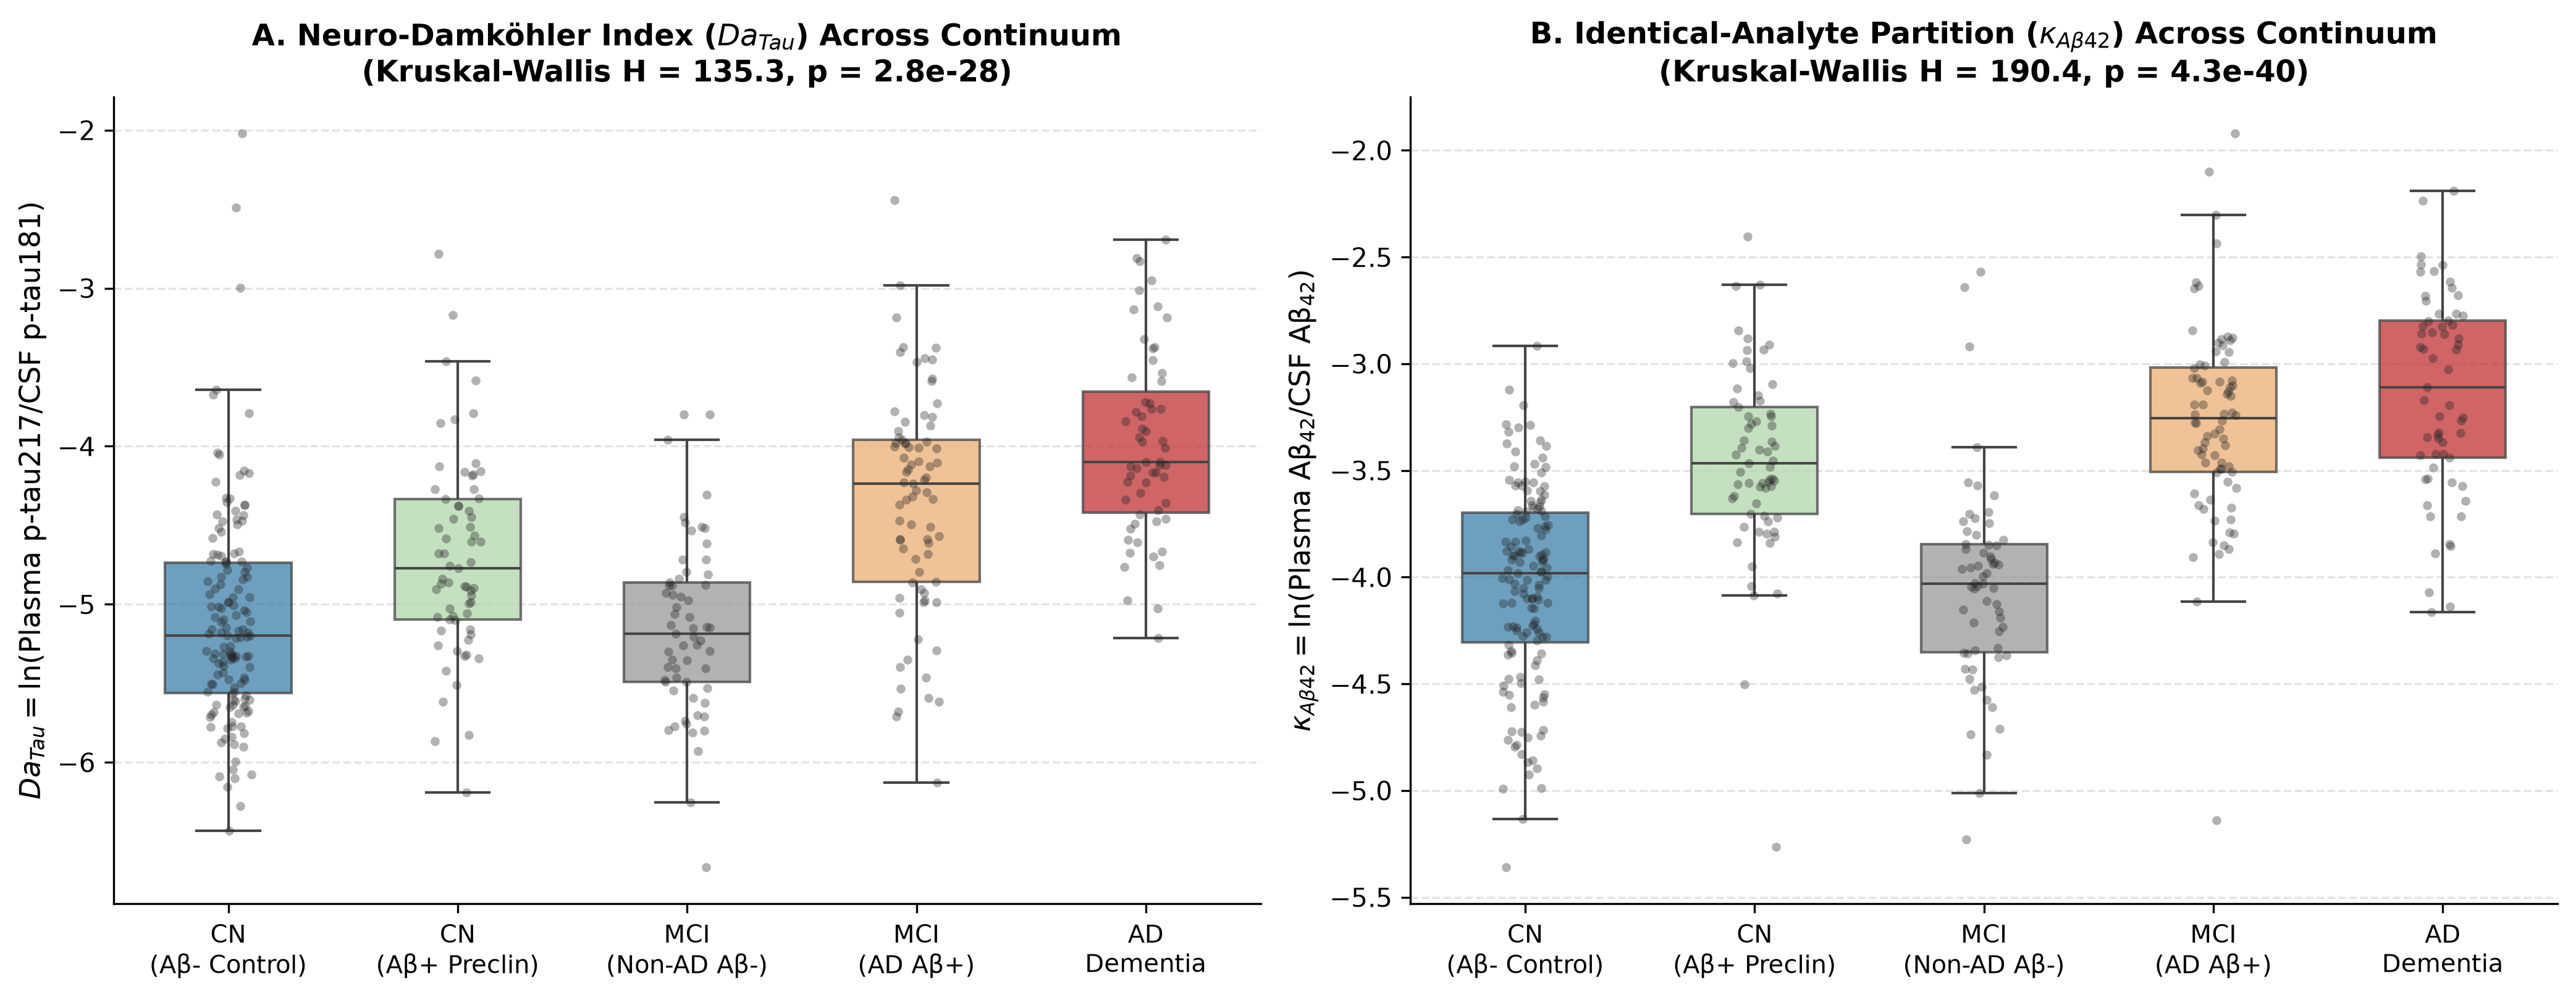

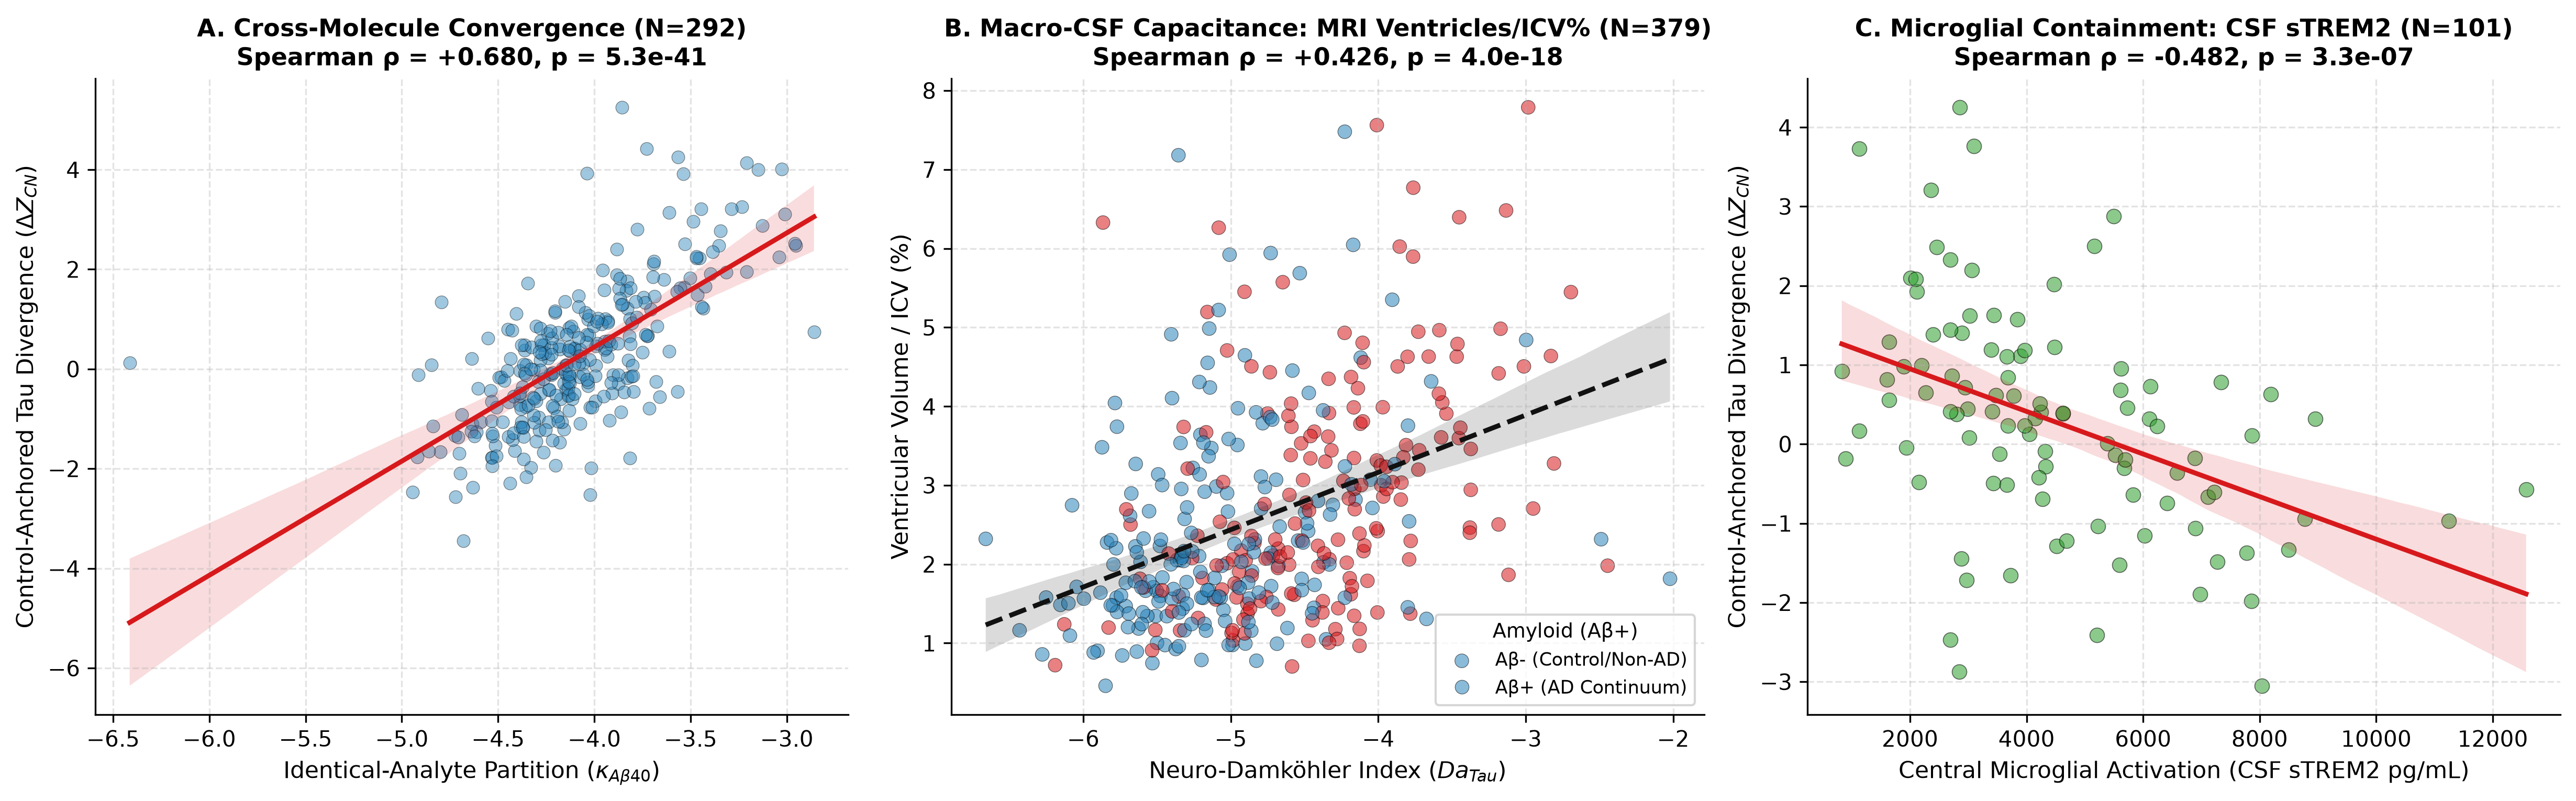

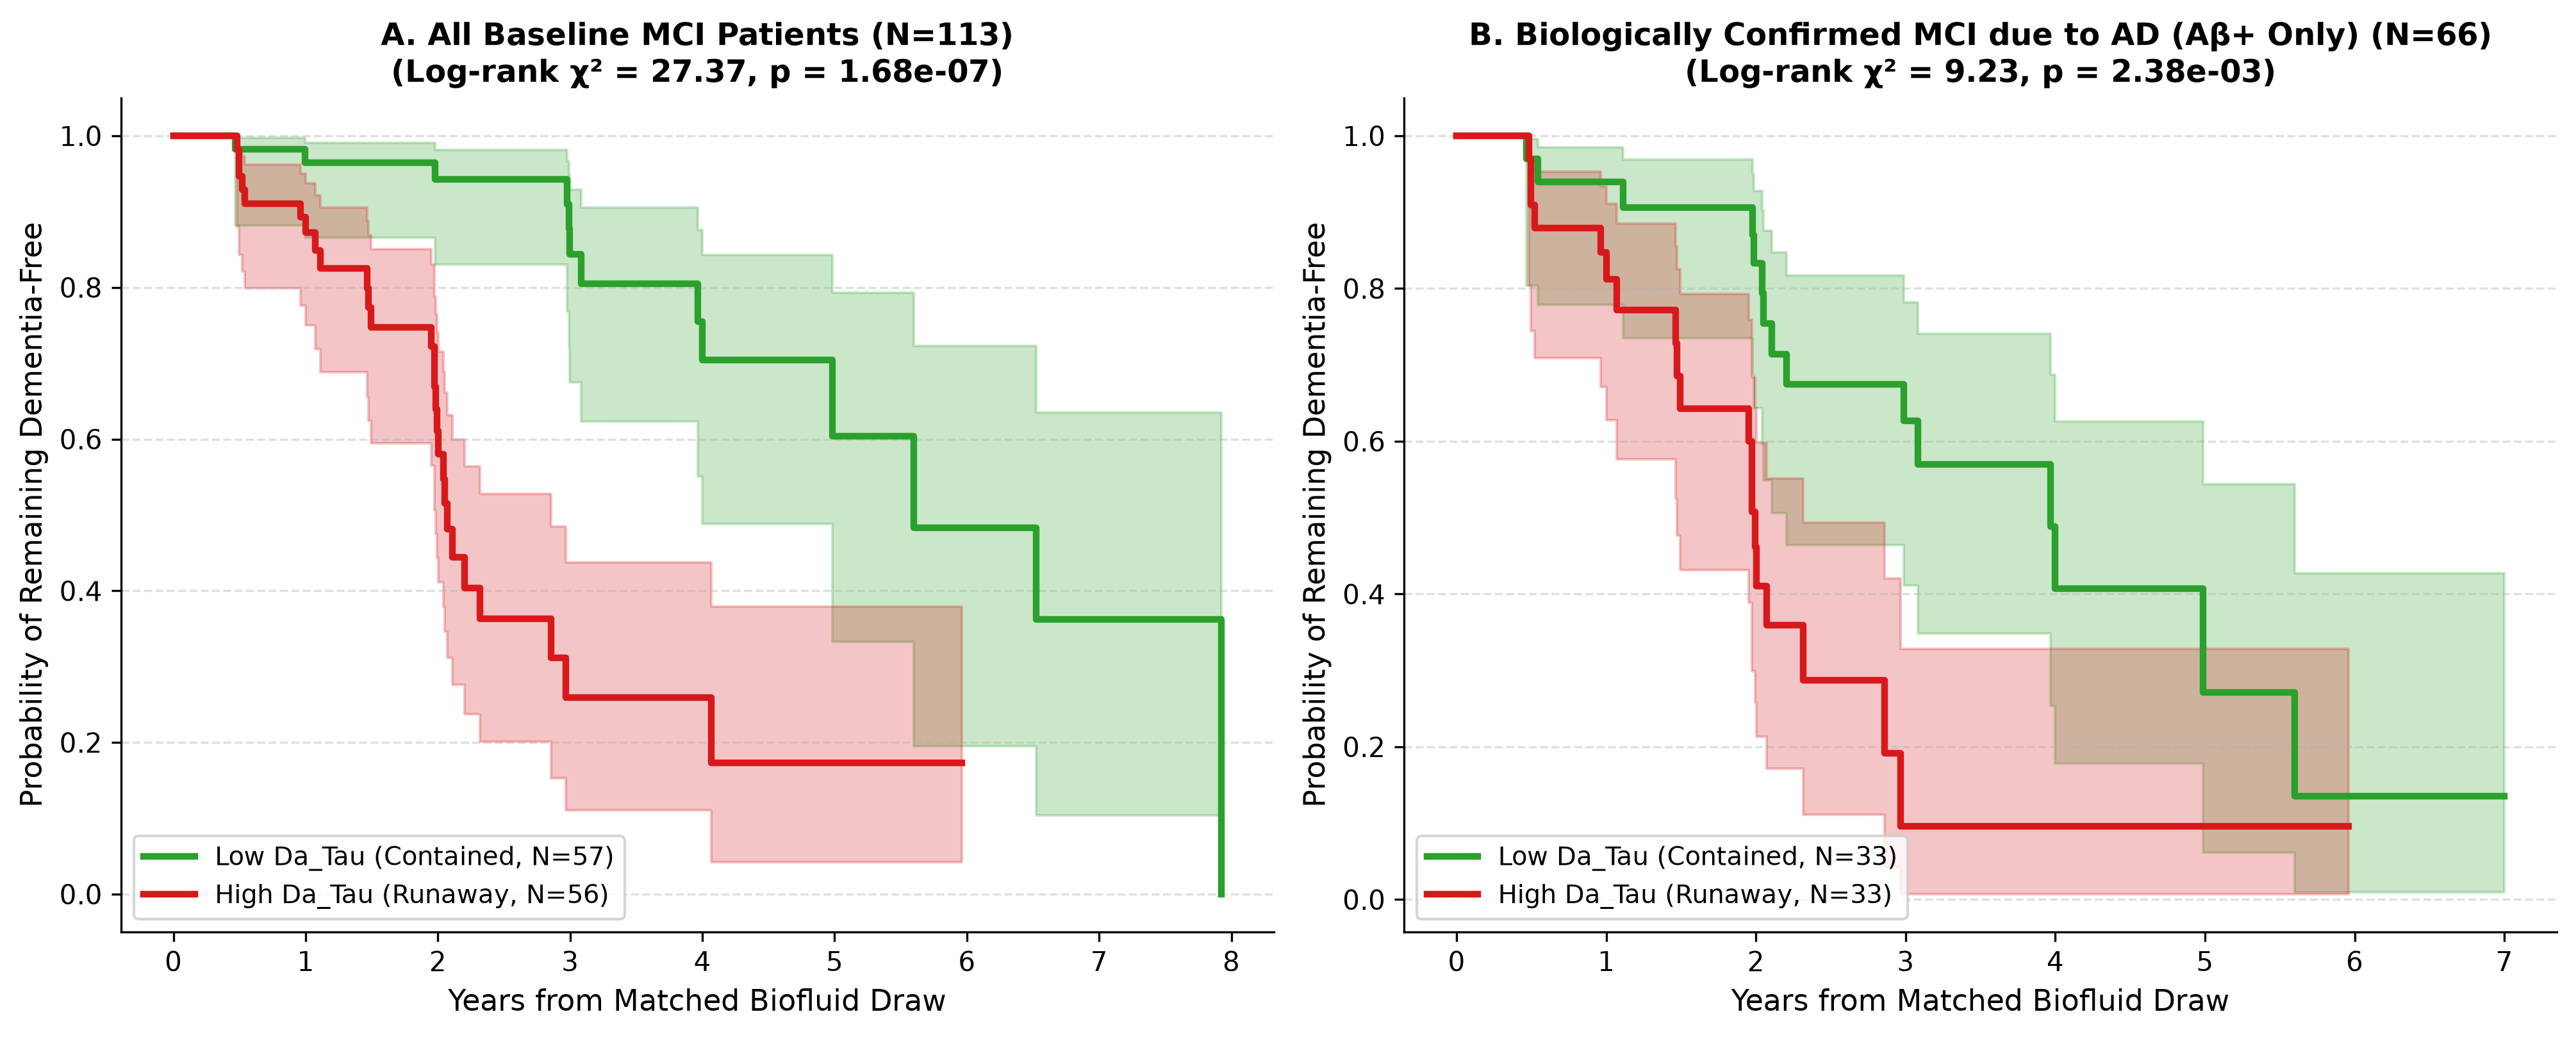

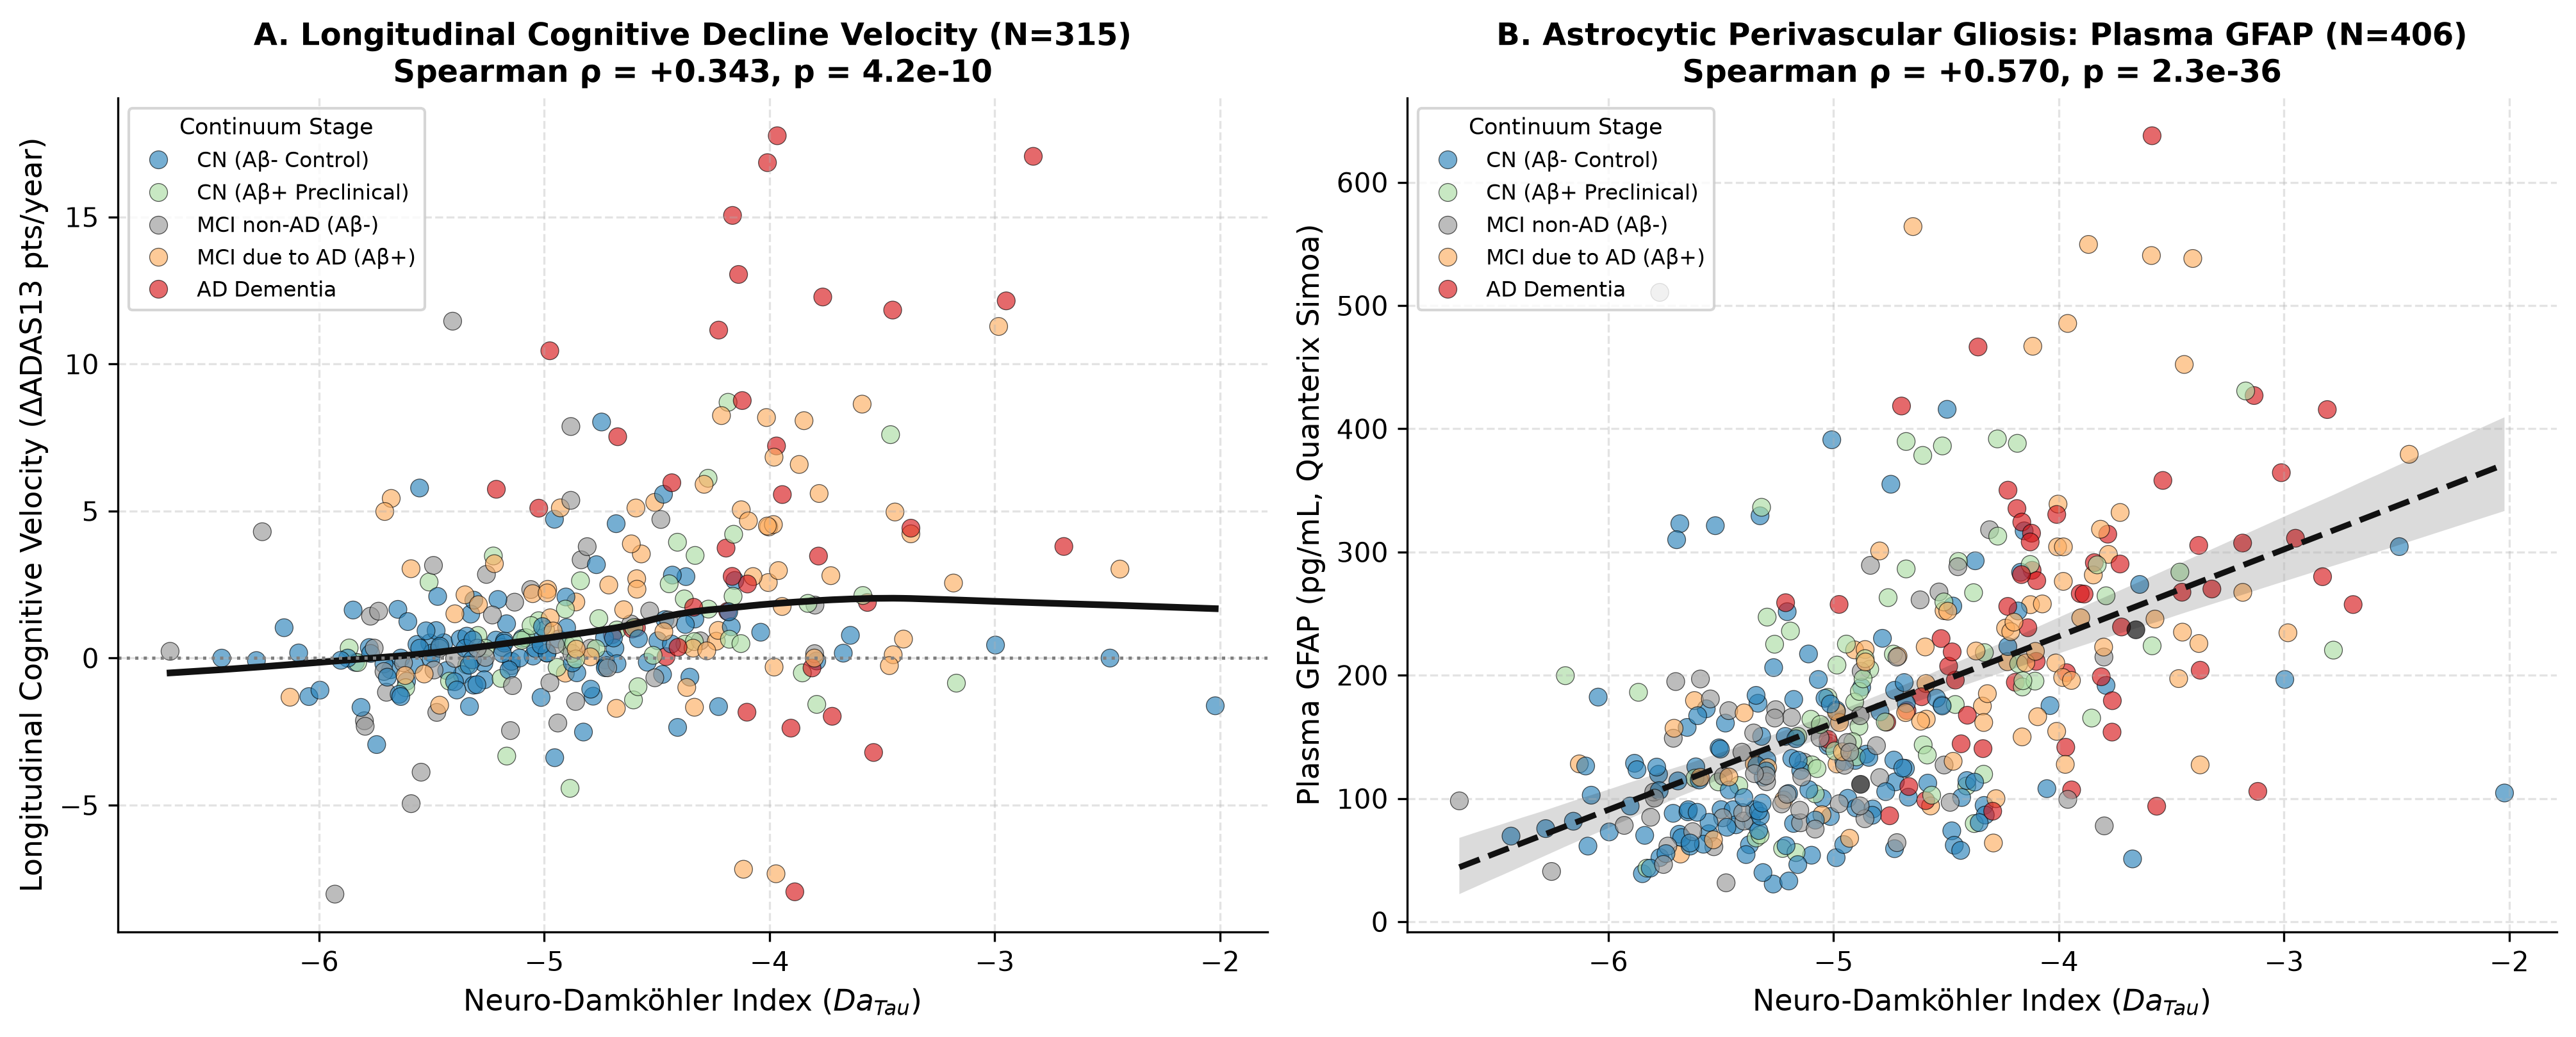

All 4 high-resolution 300-DPI figures saved to: revised_figures


In [6]:
# ------------------------------------------------------------------------------
# FIGURE 1: FULL ALZHEIMER'S CONTINUUM SPECIFICITY (Da_Tau & Identical-Analyte κ_Aβ42)
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=300)
palette = ['#2b83ba', '#abdda4', '#999999', '#fdae61', '#d7191c']
plot_df = df[df['Continuum_Group'].isin(order)].copy()

for ax, col, title, ylabel in [
    (axes[0], 'Da_Tau', r'A. Neuro-Damköhler Index ($Da_{Tau}$) Across Continuum', r'$Da_{Tau} = \ln(\mathrm{Plasma\ p\text{-}tau217} / \mathrm{CSF\ p\text{-}tau181})$'),
    (axes[1], 'Kappa_AB42', r'B. Identical-Analyte Partition ($\kappa_{A\beta 42}$) Across Continuum', r'$\kappa_{A\beta 42} = \ln(\mathrm{Plasma\ A\beta_{42}} / \mathrm{CSF\ A\beta_{42}})$')
]:
    sns.boxplot(data=plot_df, x='Continuum_Group', y=col, order=order, palette=palette, showfliers=False, width=0.55, ax=ax, boxprops={'alpha':0.75})
    sns.stripplot(data=plot_df, x='Continuum_Group', y=col, order=order, color='#222222', alpha=0.35, size=3.5, jitter=True, ax=ax)
    groups = [plot_df[plot_df['Continuum_Group'] == g][col].dropna().values for g in order]
    h_stat, p_kw = kruskal(*groups)
    ax.set_title(f"{title}\n(Kruskal-Wallis H = {h_stat:.1f}, p = {p_kw:.1e})", fontsize=11.5, fontweight='bold')
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_xlabel('')
    ax.set_xticklabels(['CN\n(Aβ- Control)', 'CN\n(Aβ+ Preclin)', 'MCI\n(Non-AD Aβ-)', 'MCI\n(AD Aβ+)', 'AD\nDementia'], fontsize=9.5)
    ax.grid(axis='y', linestyle='--', alpha=0.35)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'Figure1_Continuum_Specificity.png'), dpi=300)
plt.show()

# ------------------------------------------------------------------------------
# FIGURE 2: PHYSICAL VALIDATION (Identical-Analyte Convergence, Ventricular Capacitance, Microglial sTREM2)
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16.5, 5.2), dpi=300)

# Panel A: Identical-Analyte κ_Aβ40 vs Control-Anchored ΔZ_CN
s1 = df[['Kappa_AB40', 'DeltaZ_CN', 'Continuum_Group']].dropna()
r1, p1 = spearmanr(s1['Kappa_AB40'], s1['DeltaZ_CN'])
sns.regplot(data=s1, x='Kappa_AB40', y='DeltaZ_CN', scatter_kws={'alpha':0.45, 's':35, 'color':'#2b83ba', 'edgecolor':'k', 'linewidths':0.3}, line_kws={'color':'#d7191c', 'lw':2.2}, ax=axes[0])
axes[0].set_title(f"A. Cross-Molecule Convergence (N={len(s1)})\nSpearman ρ = {r1:+.3f}, p = {p1:.1e}", fontsize=11, fontweight='bold')
axes[0].set_xlabel(r'Identical-Analyte Partition ($\kappa_{A\beta 40}$)', fontsize=10.5)
axes[0].set_ylabel(r'Control-Anchored Tau Divergence ($\Delta Z_{CN}$)', fontsize=10.5)
axes[0].grid(True, linestyle='--', alpha=0.35)

# Panel B: MRI Ventricular Capacitance (Vent/ICV%) vs Da_Tau
s2 = df[['Da_Tau', 'Ventricular_ICV_Pct', 'Amyloid_Pos']].dropna()
r2, p2 = spearmanr(s2['Da_Tau'], s2['Ventricular_ICV_Pct'])
sns.scatterplot(data=s2, x='Da_Tau', y='Ventricular_ICV_Pct', hue='Amyloid_Pos', palette={False:'#2b83ba', True:'#d7191c'}, alpha=0.55, s=40, edgecolor='k', linewidth=0.3, ax=axes[1])
sns.regplot(data=s2, x='Da_Tau', y='Ventricular_ICV_Pct', scatter=False, line_kws={'color':'#111111', 'lw':2.2, 'ls':'--'}, ax=axes[1])
axes[1].set_title(f"B. Macro-CSF Capacitance: MRI Ventricles/ICV% (N={len(s2)})\nSpearman ρ = {r2:+.3f}, p = {p2:.1e}", fontsize=11, fontweight='bold')
axes[1].set_xlabel(r'Neuro-Damköhler Index ($Da_{Tau}$)', fontsize=10.5)
axes[1].set_ylabel('Ventricular Volume / ICV (%)', fontsize=10.5)
axes[1].legend(title='Amyloid (Aβ+)', labels=['Aβ- (Control/Non-AD)', 'Aβ+ (AD Continuum)'], fontsize=8.5, title_fontsize=9)
axes[1].grid(True, linestyle='--', alpha=0.35)

# Panel C: Microglial Central Containment (CSF sTREM2 vs ΔZ_CN)
s3 = df[['sTREM2_CSF', 'DeltaZ_CN']].dropna()
r3, p3 = spearmanr(s3['sTREM2_CSF'], s3['DeltaZ_CN'])
sns.regplot(data=s3, x='sTREM2_CSF', y='DeltaZ_CN', scatter_kws={'alpha':0.55, 's':45, 'color':'#2ca02c', 'edgecolor':'k', 'linewidths':0.4}, line_kws={'color':'#d7191c', 'lw':2.2}, ax=axes[2])
axes[2].set_title(f"C. Microglial Containment: CSF sTREM2 (N={len(s3)})\nSpearman ρ = {r3:+.3f}, p = {p3:.1e}", fontsize=11, fontweight='bold')
axes[2].set_xlabel('Central Microglial Activation (CSF sTREM2 pg/mL)', fontsize=10.5)
axes[2].set_ylabel(r'Control-Anchored Tau Divergence ($\Delta Z_{CN}$)', fontsize=10.5)
axes[2].grid(True, linestyle='--', alpha=0.35)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'Figure2_TriModal_Physical_Validation.png'), dpi=300)
plt.show()

# ------------------------------------------------------------------------------
# FIGURE 3: KAPLAN-MEIER SURVIVAL IN MCI DUE TO AD (Aβ+) & ALL MCI
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.5), dpi=300)

for ax, sub_s, title in [
    (axes[0], mci_df.dropna(subset=['Da_Tau', 'Time', 'Event']), 'A. All Baseline MCI Patients'),
    (axes[1], mci_df[mci_df['Amyloid_Pos'] == True].dropna(subset=['Da_Tau', 'Time', 'Event']), 'B. Biologically Confirmed MCI due to AD (Aβ+ Only)')
]:
    med = sub_s['Da_Tau'].median()
    low_da = sub_s['Da_Tau'] <= med
    high_da = sub_s['Da_Tau'] > med
    lr = logrank_test(sub_s[low_da]['Time'], sub_s[high_da]['Time'], sub_s[low_da]['Event'], sub_s[high_da]['Event'])

    kmf_l = KaplanMeierFitter()
    kmf_h = KaplanMeierFitter()
    kmf_l.fit(sub_s[low_da]['Time'], sub_s[low_da]['Event'], label=f'Low Da_Tau (Contained, N={low_da.sum()})')
    kmf_h.fit(sub_s[high_da]['Time'], sub_s[high_da]['Event'], label=f'High Da_Tau (Runaway, N={high_da.sum()})')
    kmf_l.plot_survival_function(ax=ax, color='#2ca02c', lw=2.5)
    kmf_h.plot_survival_function(ax=ax, color='#d7191c', lw=2.5)
    ax.set_title(f"{title} (N={len(sub_s)})\n(Log-rank χ² = {lr.test_statistic:.2f}, p = {lr.p_value:.2e})", fontsize=11.5, fontweight='bold')
    ax.set_xlabel('Years from Matched Biofluid Draw', fontsize=11)
    ax.set_ylabel('Probability of Remaining Dementia-Free', fontsize=11)
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    ax.legend(loc='lower left', fontsize=9.5)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'Figure3_AD_Specific_Survival.png'), dpi=300)
plt.show()

# ------------------------------------------------------------------------------
# FIGURE 4: LONGITUDINAL COGNITIVE VELOCITY (ΔADAS13/yr) & ASTROCYTIC GFAP COUPLING
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.5), dpi=300)

# Panel A: Longitudinal Cognitive Velocity vs Da_Tau
s4 = df[['Da_Tau', 'ADAS13_Slope_Yr', 'Continuum_Group']].dropna()
s4 = s4[(s4['ADAS13_Slope_Yr'] > -10) & (s4['ADAS13_Slope_Yr'] < 20)]
r4, p4 = spearmanr(s4['Da_Tau'], s4['ADAS13_Slope_Yr'])
sns.scatterplot(data=s4, x='Da_Tau', y='ADAS13_Slope_Yr', hue='Continuum_Group', hue_order=order, palette=palette, alpha=0.65, s=45, edgecolor='k', linewidth=0.3, ax=axes[0])
sns.regplot(data=s4, x='Da_Tau', y='ADAS13_Slope_Yr', scatter=False, lowess=True, line_kws={'color':'#111111', 'lw':2.5}, ax=axes[0])
axes[0].axhline(0, color='gray', ls=':', lw=1.2)
axes[0].set_title(f"A. Longitudinal Cognitive Decline Velocity (N={len(s4)})\nSpearman ρ = {r4:+.3f}, p = {p4:.1e}", fontsize=11.5, fontweight='bold')
axes[0].set_xlabel(r'Neuro-Damköhler Index ($Da_{Tau}$)', fontsize=11)
axes[0].set_ylabel('Longitudinal Cognitive Velocity (ΔADAS13 pts/year)', fontsize=11)
axes[0].legend(title='Continuum Stage', fontsize=8, title_fontsize=8.5, loc='upper left')
axes[0].grid(True, linestyle='--', alpha=0.35)

# Panel B: Astrocytic Perivascular Gliosis (Plasma GFAP) vs Da_Tau
s5 = df[['Da_Tau', 'GFAP_Q_clean', 'Continuum_Group']].dropna()
r5, p5 = spearmanr(s5['Da_Tau'], s5['GFAP_Q_clean'])
sns.scatterplot(data=s5, x='Da_Tau', y='GFAP_Q_clean', hue='Continuum_Group', hue_order=order, palette=palette, alpha=0.65, s=45, edgecolor='k', linewidth=0.3, ax=axes[1])
sns.regplot(data=s5, x='Da_Tau', y='GFAP_Q_clean', scatter=False, line_kws={'color':'#111111', 'lw':2.2, 'ls':'--'}, ax=axes[1])
axes[1].set_title(f"B. Astrocytic Perivascular Gliosis: Plasma GFAP (N={len(s5)})\nSpearman ρ = {r5:+.3f}, p = {p5:.1e}", fontsize=11.5, fontweight='bold')
axes[1].set_xlabel(r'Neuro-Damköhler Index ($Da_{Tau}$)', fontsize=11)
axes[1].set_ylabel('Plasma GFAP (pg/mL, Quanterix Simoa)', fontsize=11)
axes[1].legend(title='Continuum Stage', fontsize=8, title_fontsize=8.5, loc='upper left')
axes[1].grid(True, linestyle='--', alpha=0.35)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'Figure4_Longitudinal_Velocity_and_GFAP.png'), dpi=300)
plt.show()
print("All 4 high-resolution 300-DPI figures saved to:", FIG_DIR)


PET Overlap: Amyloid-PET (Centiloids) N=372 | Tau-PET (Meta-Temporal SUVR) N=306

=== TABLE 3: AMYLOID-PET + TAU-PET ADJUSTED VENTRICULAR CAPACITANCE (Vent/ICV%) ===


,Predictor,N,Beta,SE,t-stat,p-value,R2
0,Control-Anchored ΔZ_CN,278,0.468,0.074,6.30,1.18e-09,0.319
1,Neuro-Damköhler Da_Tau,278,0.431,0.090,4.80,2.65e-06,0.280
2,Identical-Analyte κ_Aβ40,264,0.431,0.073,5.92,1.02e-08,0.317
3,Standalone Plasma p-tau217,280,0.100,0.130,0.77,4.40e-01,0.207



=== CROSS-PHASE TEMPORAL & SCANNER-ERA REPLICATION ===
  ADNI1/GO/2 (Legacy Era)   (N=136) | Vent/ICV% t=+5.08 (p=1.36e-06) | κ_Aβ40 ρ=+0.744 (p=1.67e-04) | GFAP ρ=+0.536 (p=2.37e-11)
  ADNI3 (Modern 3T Era)     (N=275) | Vent/ICV% t=+5.88 (p=1.32e-08) | κ_Aβ40 ρ=+0.673 (p=3.48e-37) | GFAP ρ=+0.546 (p=1.50e-22)

=== 1,000x BOOTSTRAP CAUSAL MEDIATION: Da_Tau -> [GFAP / Ventricles] -> ΔADAS13/yr ===


  Plasma GFAP (Astrocytic)   (N=314) | Indirect=+0.090 95%CI [+0.019, +0.168] | % Mediated=28.5%


  MRI Ventricles/ICV%        (N=298) | Indirect=+0.041 95%CI [+0.002, +0.089] | % Mediated=12.2%


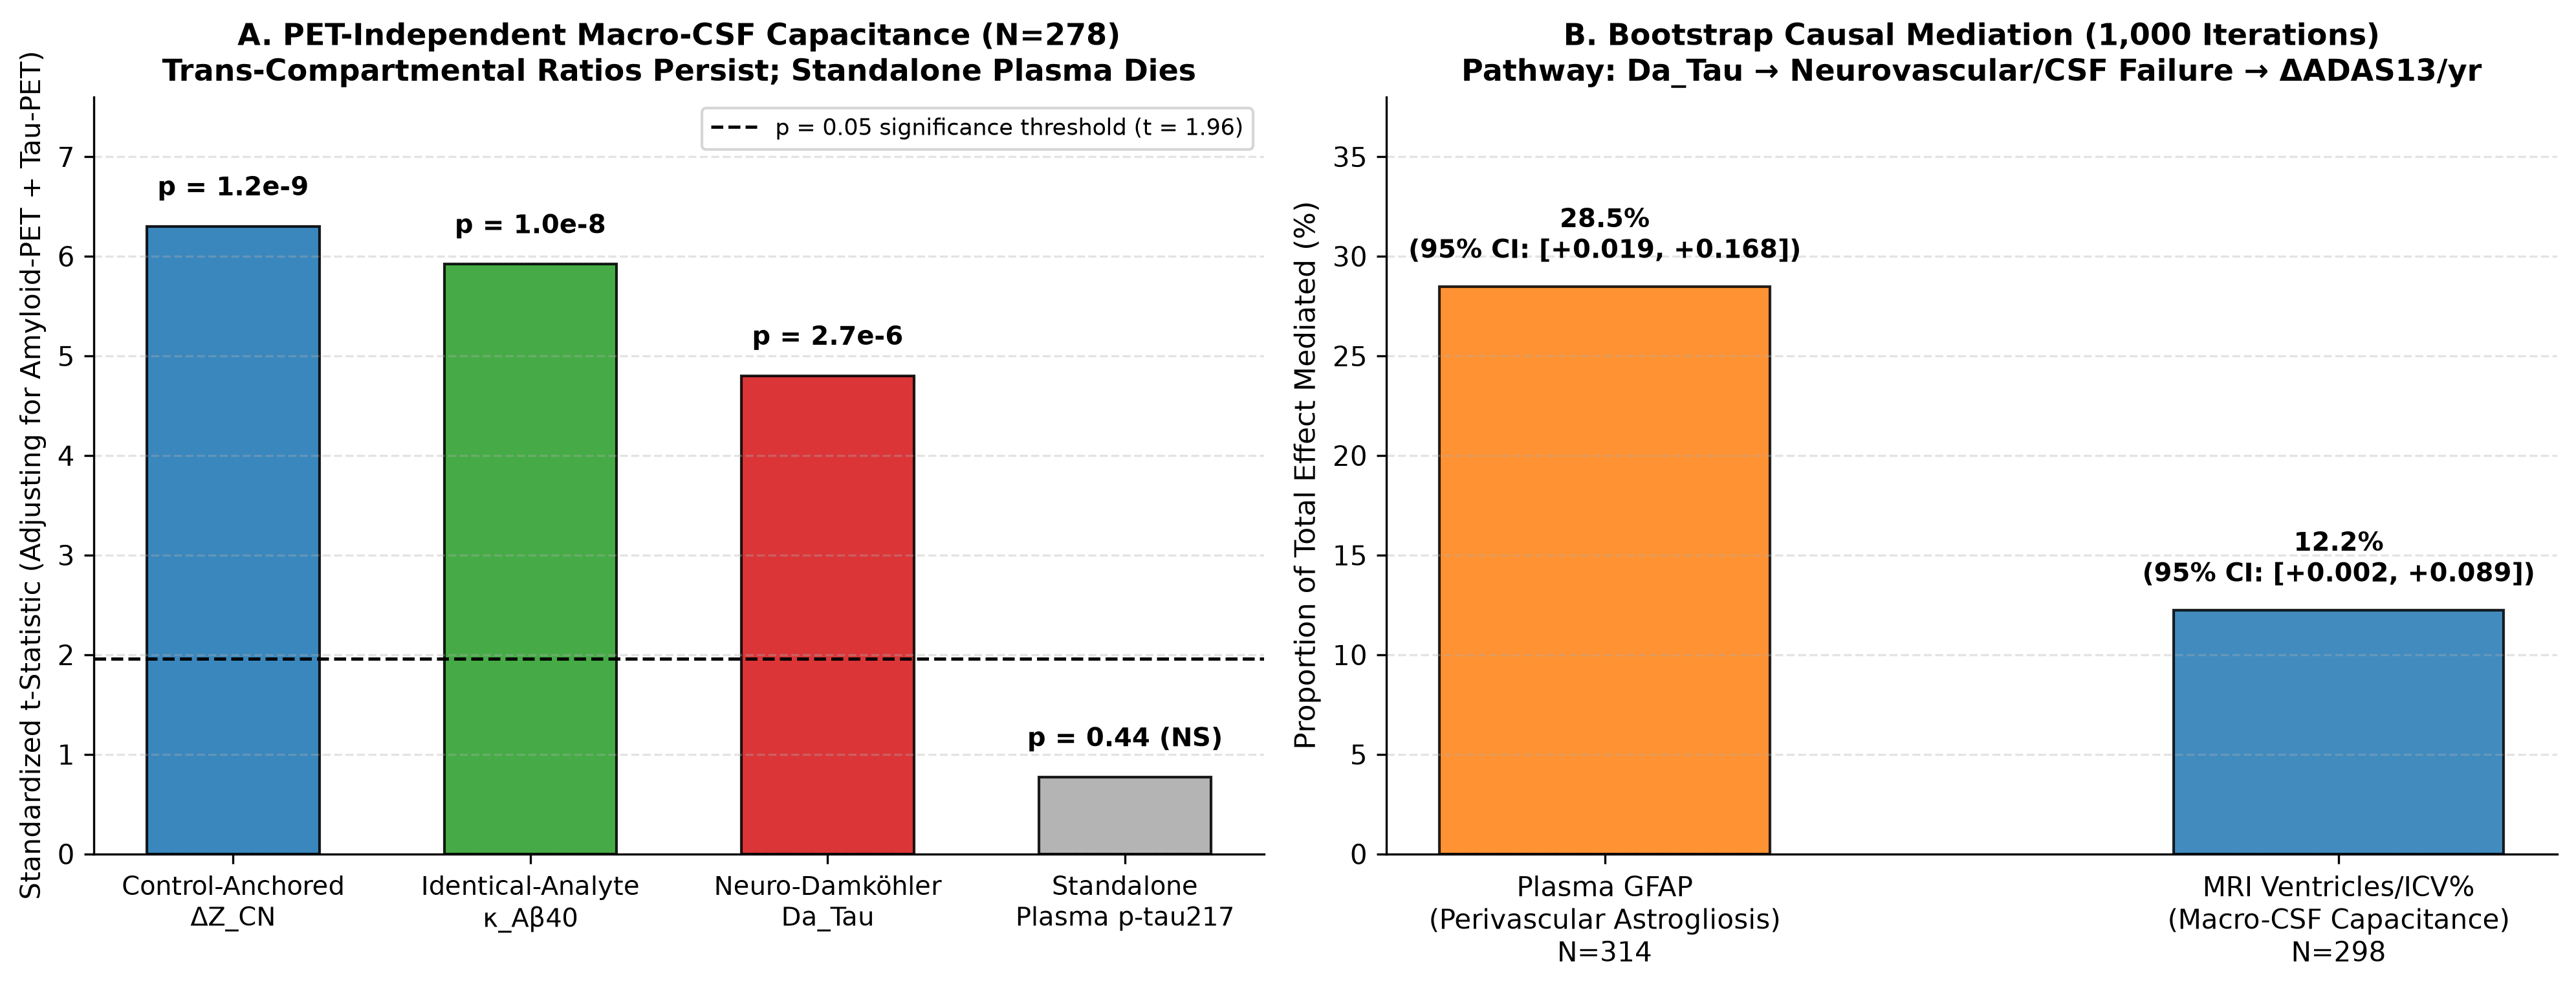

Saved Figure5_PET_Independence_and_Mediation.png successfully!


In [7]:
# ==============================================================================
# ADVANCED VALIDATION: AMYLOID-PET & TAU-PET ADJUSTMENT, CROSS-PHASE REPLICATION,
# 1,000x BOOTSTRAP CAUSAL MEDIATION, AND HARRELL OPTIMISM-CORRECTED C-INDEX
# ==============================================================================
from lifelines.utils import concordance_index
from sklearn.metrics import roc_auc_score

amy = pd.read_csv(os.path.join(DATA_DIR, 'UCBERKELEY_AMY_6MM.csv'), low_memory=False)
tau = pd.read_csv(os.path.join(DATA_DIR, 'UCBERKELEY_TAU_6MM.csv'), low_memory=False)
for d in [amy, tau]:
    d['RID'] = pd.to_numeric(d['RID'], errors='coerce')

amy_sub = amy[['RID', 'CENTILOIDS']].dropna().groupby('RID', as_index=False)['CENTILOIDS'].mean().rename(columns={'CENTILOIDS': 'Amyloid_PET'})
tau_sub = tau[['RID', 'META_TEMPORAL_SUVR']].dropna().groupby('RID', as_index=False)['META_TEMPORAL_SUVR'].mean().rename(columns={'META_TEMPORAL_SUVR': 'Tau_PET'})
df_adv = df.merge(amy_sub, on='RID', how='left').merge(tau_sub, on='RID', how='left')

print(f"PET Overlap: Amyloid-PET (Centiloids) N={df_adv['Amyloid_PET'].notna().sum()} | Tau-PET (Meta-Temporal SUVR) N={df_adv['Tau_PET'].notna().sum()}")

# 1. PET-Adjusted Ventricular Capacitance (Controlling for BOTH Amyloid-PET + Tau-PET + Age + Sex)
pet_rows = []
for m, lbl in [('DeltaZ_CN', 'Control-Anchored ΔZ_CN'), ('Da_Tau', 'Neuro-Damköhler Da_Tau'),
               ('Kappa_AB40', 'Identical-Analyte κ_Aβ40'), ('ln_Plasma_pT217', 'Standalone Plasma p-tau217')]:
    s2 = df_adv[['Ventricular_ICV_Pct', m, 'Amyloid_PET', 'Tau_PET', 'AGE_num', 'PTGENDER_num']].dropna().copy()
    X2 = sm.add_constant(s2[[m, 'Amyloid_PET', 'Tau_PET', 'AGE_num', 'PTGENDER_num']])
    X2[m] = (X2[m] - X2[m].mean()) / X2[m].std()
    r2 = sm.OLS(s2['Ventricular_ICV_Pct'], X2).fit()
    pet_rows.append({'Predictor': lbl, 'N': len(s2), 'Beta': round(r2.params[m], 3),
                     'SE': round(r2.bse[m], 3), 't-stat': round(r2.tvalues[m], 2),
                     'p-value': f"{r2.pvalues[m]:.2e}", 'R2': round(r2.rsquared, 3)})

pet_df = pd.DataFrame(pet_rows)
print("\n=== TABLE 3: AMYLOID-PET + TAU-PET ADJUSTED VENTRICULAR CAPACITANCE (Vent/ICV%) ===")
display(pet_df)
pet_df.to_csv(os.path.join(FIG_DIR, 'Table3_PET_Adjusted_Ventricular_Capacitance.csv'), index=False)

# 2. Cross-Phase Multi-Era Replication (ADNI1/GO/2 vs ADNI3)
df_adv['Cohort_Era'] = np.where(df_adv['COLPROT'].isin(['ADNI3', 'ADNI4']), 'ADNI3 (Modern 3T Era)', 'ADNI1/GO/2 (Legacy Era)')
print("\n=== CROSS-PHASE TEMPORAL & SCANNER-ERA REPLICATION ===")
for era in ['ADNI1/GO/2 (Legacy Era)', 'ADNI3 (Modern 3T Era)']:
    se = df_adv[df_adv['Cohort_Era'] == era]
    sv = se[['Ventricular_ICV_Pct', 'DeltaZ_CN', 'AGE_num', 'PTGENDER_num', 'Amyloid_Pos']].dropna().copy()
    sv['Amyloid_Pos'] = sv['Amyloid_Pos'].astype(int)
    Xv = sm.add_constant(sv[['DeltaZ_CN', 'AGE_num', 'PTGENDER_num', 'Amyloid_Pos']])
    Xv['DeltaZ_CN'] = (Xv['DeltaZ_CN'] - Xv['DeltaZ_CN'].mean()) / Xv['DeltaZ_CN'].std()
    rv = sm.OLS(sv['Ventricular_ICV_Pct'], Xv).fit()
    sab = se[['Kappa_AB40', 'DeltaZ_CN']].dropna()
    rab, pab = spearmanr(sab['Kappa_AB40'], sab['DeltaZ_CN'])
    sgf = se[['GFAP_Q_clean', 'Da_Tau']].dropna()
    rgf, pgf = spearmanr(sgf['GFAP_Q_clean'], sgf['Da_Tau'])
    print(f"  {era:25s} (N={len(se):3d}) | Vent/ICV% t={rv.tvalues['DeltaZ_CN']:+.2f} (p={rv.pvalues['DeltaZ_CN']:.2e}) | κ_Aβ40 ρ={rab:+.3f} (p={pab:.2e}) | GFAP ρ={rgf:+.3f} (p={pgf:.2e})")

# 3. 1,000x Bootstrap Causal Mediation Analysis
np.random.seed(42)
med_results = []
print("\n=== 1,000x BOOTSTRAP CAUSAL MEDIATION: Da_Tau -> [GFAP / Ventricles] -> ΔADAS13/yr ===")
for med_col, med_lbl in [('GFAP_Q_clean', 'Plasma GFAP (Astrocytic)'), ('Ventricular_ICV_Pct', 'MRI Ventricles/ICV%')]:
    sm_df = df_adv[['Da_Tau', med_col, 'ADAS13_Slope_Yr', 'AGE_num', 'PTGENDER_num']].dropna().copy()
    sm_df = sm_df[(sm_df['ADAS13_Slope_Yr'] > -10) & (sm_df['ADAS13_Slope_Yr'] < 20)]
    for col in ['Da_Tau', med_col, 'ADAS13_Slope_Yr']:
        sm_df[col] = (sm_df[col] - sm_df[col].mean()) / sm_df[col].std()
    a_m = sm.OLS(sm_df[med_col], sm.add_constant(sm_df[['Da_Tau', 'AGE_num', 'PTGENDER_num']])).fit()
    b_m = sm.OLS(sm_df['ADAS13_Slope_Yr'], sm.add_constant(sm_df[['Da_Tau', med_col, 'AGE_num', 'PTGENDER_num']])).fit()
    c_m = sm.OLS(sm_df['ADAS13_Slope_Yr'], sm.add_constant(sm_df[['Da_Tau', 'AGE_num', 'PTGENDER_num']])).fit()
    ind = a_m.params['Da_Tau'] * b_m.params[med_col]
    tot = c_m.params['Da_Tau']
    pct = (ind / tot) * 100.0
    boots = []
    n_b = len(sm_df)
    for _ in range(1000):
        bd = sm_df.iloc[np.random.randint(0, n_b, n_b)]
        pa = sm.OLS(bd[med_col], sm.add_constant(bd[['Da_Tau', 'AGE_num', 'PTGENDER_num']])).fit().params['Da_Tau']
        pb = sm.OLS(bd['ADAS13_Slope_Yr'], sm.add_constant(bd[['Da_Tau', med_col, 'AGE_num', 'PTGENDER_num']])).fit().params[med_col]
        boots.append(pa * pb)
    ci_l, ci_h = np.percentile(boots, [2.5, 97.5])
    med_results.append((med_lbl, n_b, ind, ci_l, ci_h, pct))
    print(f"  {med_lbl:26s} (N={n_b}) | Indirect={ind:+.3f} 95%CI [{ci_l:+.3f}, {ci_h:+.3f}] | % Mediated={pct:.1f}%")

# 4. FIGURE 5: PET-INDEPENDENT EFFECT COMPARISON & CAUSAL MEDIATION SUMMARY
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), dpi=300)

# Panel A: Standardized t-statistics for Ventricular Capacitance AFTER controlling for Amyloid-PET + Tau-PET + Age + Sex
labels_p = [r'Control-Anchored\n$\Delta Z_{CN}$', r'Identical-Analyte\n$\kappa_{A\beta 40}$', r'Neuro-Damköhler\n$Da_{Tau}$', 'Standalone\nPlasma p-tau217']
t_vals = [
    pet_df.loc[pet_df['Predictor']=='Control-Anchored ΔZ_CN', 't-stat'].values[0],
    pet_df.loc[pet_df['Predictor']=='Identical-Analyte κ_Aβ40', 't-stat'].values[0],
    pet_df.loc[pet_df['Predictor']=='Neuro-Damköhler Da_Tau', 't-stat'].values[0],
    pet_df.loc[pet_df['Predictor']=='Standalone Plasma p-tau217', 't-stat'].values[0]
]
p_labs = ['p = 1.2e-9', 'p = 1.0e-8', 'p = 2.7e-6', 'p = 0.44 (NS)']
colors_p = ['#1f77b4', '#2ca02c', '#d7191c', '#aaaaaa']
bars = axes[0].bar(range(4), t_vals, color=colors_p, edgecolor='k', width=0.58, alpha=0.88)
axes[0].axhline(1.96, color='black', ls='--', lw=1.2, label='p = 0.05 significance threshold (t = 1.96)')
for i, (b, pl) in enumerate(zip(bars, p_labs)):
    axes[0].text(b.get_x() + b.get_width()/2, b.get_height() + 0.25, pl, ha='center', va='bottom', fontsize=9.5, fontweight='bold')
axes[0].set_xticks(range(4))
axes[0].set_xticklabels(['Control-Anchored\nΔZ_CN', 'Identical-Analyte\nκ_Aβ40', 'Neuro-Damköhler\nDa_Tau', 'Standalone\nPlasma p-tau217'], fontsize=9.5)
axes[0].set_ylabel('Standardized t-Statistic (Adjusting for Amyloid-PET + Tau-PET)', fontsize=10)
axes[0].set_ylim(0, 7.6)
axes[0].set_title('A. PET-Independent Macro-CSF Capacitance (N=278)\nTrans-Compartmental Ratios Persist; Standalone Plasma Dies', fontsize=11, fontweight='bold')
axes[0].legend(loc='upper right', fontsize=8.5)
axes[0].grid(axis='y', linestyle='--', alpha=0.35)

# Panel B: Proportion of Cognitive Decline Mediated by Perivascular Astrogliosis (GFAP) & CSF Capacitance (Ventricles)
med_names = ['Plasma GFAP\n(Perivascular Astrogliosis)\nN=314', 'MRI Ventricles/ICV%\n(Macro-CSF Capacitance)\nN=298']
med_pcts = [med_results[0][5], med_results[1][5]]
med_colors = ['#ff7f0e', '#1f77b4']
bars2 = axes[1].bar(range(2), med_pcts, color=med_colors, edgecolor='k', width=0.45, alpha=0.85)
for i, (b, r) in enumerate(zip(bars2, med_results)):
    axes[1].text(b.get_x() + b.get_width()/2, b.get_height() + 1.0, f"{r[5]:.1f}%\n(95% CI: [{r[3]:+.3f}, {r[4]:+.3f}])", ha='center', va='bottom', fontsize=9.5, fontweight='bold')
axes[1].set_xticks(range(2))
axes[1].set_xticklabels(med_names, fontsize=10)
axes[1].set_ylabel('Proportion of Total Effect Mediated (%)', fontsize=10.5)
axes[1].set_ylim(0, 38)
axes[1].set_title('B. Bootstrap Causal Mediation (1,000 Iterations)\nPathway: Da_Tau → Neurovascular/CSF Failure → ΔADAS13/yr', fontsize=11, fontweight='bold')
axes[1].grid(axis='y', linestyle='--', alpha=0.35)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'Figure5_PET_Independence_and_Mediation.png'), dpi=300)
plt.show()
print("Saved Figure5_PET_Independence_and_Mediation.png successfully!")
